In [1]:
!pip install -q transformers torch matplotlib

In [2]:
import torch
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, AutoModel

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
sentence = "The animal didn't cross the street because it was too tired"

print("Input Sentence:")
print(sentence)

Input Sentence:
The animal didn't cross the street because it was too tired



Loading model: bert-base-uncased


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (9 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Number of layers: 12
Number of attention heads: 12
'it' attends most to:
[('The', 0.68), ('because', 0.13), ('street', 0.04), ('animal', 0.03)]
Per-head target of 'it':
['The', 'The', 'The', 'The', 'because', 'The', 'The', 'The', 'The', 'The', 'The', 'The']


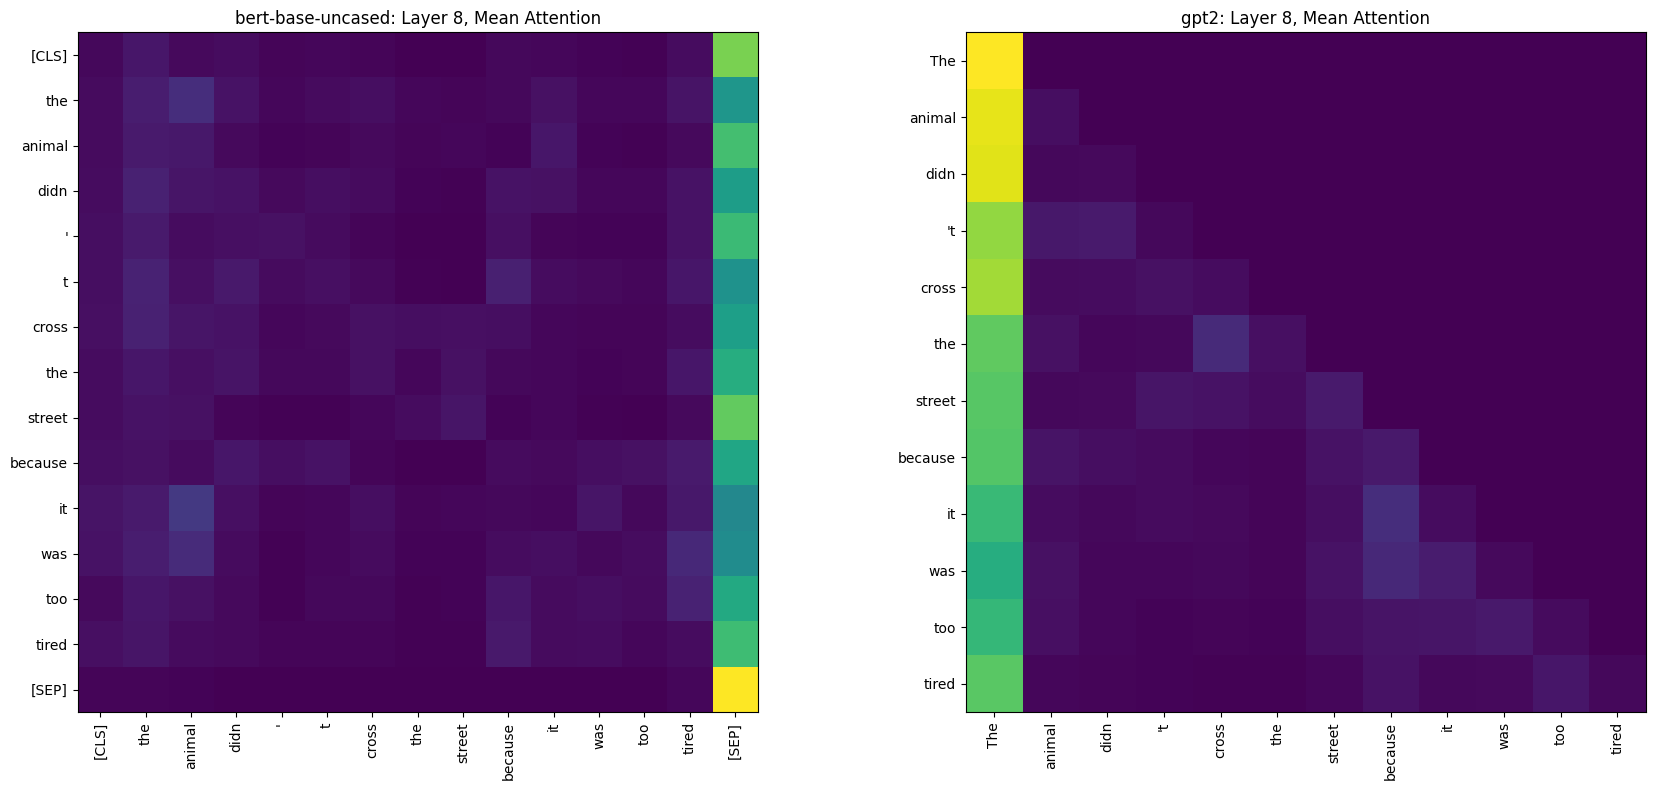

In [4]:
models = ["bert-base-uncased", "gpt2"]

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, model_id in zip(axes, models):

    print("\nLoading model:", model_id)

    tokenizer = AutoTokenizer.from_pretrained(model_id)

    model = AutoModel.from_pretrained(
        model_id,
        output_attentions=True,
        attn_implementation="eager"
    ).eval()

    inputs = tokenizer(sentence, return_tensors="pt")

    with torch.no_grad():
        outputs = model(**inputs)

    attentions = outputs.attentions

    tokens = [
        t.replace("\u0120", "")
        for t in tokenizer.convert_ids_to_tokens(inputs.input_ids[0])
    ]

    layer = len(attentions) - 4

    avg = attentions[layer][0].mean(0)

    ax.imshow(avg.numpy(), cmap="viridis")

    ax.set_xticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=90)

    ax.set_yticks(range(len(tokens)))
    ax.set_yticklabels(tokens)

    ax.set_title(
        f"{model_id}: Layer {layer}, Mean Attention"
    )

    print("Number of layers:", len(attentions))
    print("Number of attention heads:", attentions[0].shape[1])

    i = tokens.index("it")

    top = avg[i].topk(4)

    print("'it' attends most to:")

    print([
        (tokens[j], round(float(v), 2))
        for v, j in zip(top.values, top.indices)
    ])

    heads = attentions[layer][0, :, i].argmax(-1)

    print("Per-head target of 'it':")

    print([tokens[j] for j in heads])

plt.tight_layout()
plt.show()

In [5]:
print("OBSERVATIONS")

print("1. BERT uses bidirectional attention.")

print("2. BERT can attend to both left and right context.")

print("3. GPT-2 uses causal attention.")

print("4. GPT-2 can attend only to previous tokens and itself.")

print("5. Attention weights show how tokens relate to each other.")

print("\nExperiment completed successfully!")

OBSERVATIONS
1. BERT uses bidirectional attention.
2. BERT can attend to both left and right context.
3. GPT-2 uses causal attention.
4. GPT-2 can attend only to previous tokens and itself.
5. Attention weights show how tokens relate to each other.

Experiment completed successfully!
